In [ ]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation

In [ ]:
visualisation = QuinexVisualisation()

### **Import Results**

In [3]:
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe2024.xlsx")
cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV'])]

In [4]:
cost_lcoe = visualisation.convert_spatial(cost_lcoe, spatial_col="spatial_scope_refined")
print(cost_lcoe["entity_base_mapping"].value_counts())

entity_base_mapping
PV    607
Name: count, dtype: int64


In [5]:
cost_lcoe[cost_lcoe["country"] == "Tanzania"]

,Unnamed: 0,publication_year,DOI,classification,entity,property,quantity_text,value_normalized_old,unit_normalized_old,quantity_normalized,...,value_normalized,unit_normalized,entity_mapping,entity_base_mapping,property_mapping,property_base_mapping,value_converted,latitude,longitude,country
3817,3817,2019,10.1016/j.solener.2019.03.010,"{'rational': None, 'system': None, 'type': None}",solar home system with an amorphous silicon PV module,LCOE,NaN,0.37,"[('€', 1.0, 'http://qudt.org/vocab/currency/EUR', None), ('kWh', -1.0, 'http://qudt.org/vocab/unit/KiloW-HR', None)]","{'quantities': array([{'modifier': '=', 'unit': array([{'exponent': 1.0, 'text': '€', 'unit_uri': 'http://qudt.org/vocab/currency/EUR', 'year': None},\n {'exponent': -1.0, 'text': 'kWh', 'unit_uri': 'http://qudt.org/vocab/unit/KiloW-HR', 'year': None}],\n dtype=object), 'value': 0.37} ],\n dtype=object), 'type': 'single_quantity'}",...,0.37,"[('€', 1, 'http://qudt.org/vocab/unit/CCY_EUR', None), ('kWh', -1, 'http://qudt.org/vocab/unit/KiloW-HR', None)]",PV,PV,Levelized Cost,Cost,0.481746,-4.875,34.575,Tanzania


In [6]:
cost_lcoe[cost_lcoe["country"] == "Mozambique"]

,Unnamed: 0,publication_year,DOI,classification,entity,property,quantity_text,value_normalized_old,unit_normalized_old,quantity_normalized,...,value_normalized,unit_normalized,entity_mapping,entity_base_mapping,property_mapping,property_base_mapping,value_converted,latitude,longitude,country
3993,3993,2023,10.1016/j.esd.2022.11.012,"{'rational': 'arbitrary', 'system': 'model', 'type': 'observation'}",solar PV mini-grid system,lowest cost of electricity (LCOE),NaN,0.47,"[('$', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('kWh', -1.0, 'http://qudt.org/vocab/unit/KiloW-HR', None)]","{'quantities': array([{'modifier': '=', 'unit': array([{'exponent': 1.0, 'text': '$', 'unit_uri': 'http://qudt.org/vocab/currency/USD', 'year': None},\n {'exponent': -1.0, 'text': 'kWh', 'unit_uri': 'http://qudt.org/vocab/unit/KiloW-HR', 'year': None}],\n dtype=object), 'value': 0.47} ],\n dtype=object), 'type': 'single_quantity'}",...,0.47,"[('$', 1, 'http://qudt.org/vocab/unit/CCY_USD', None), ('kWh', -1, 'http://qudt.org/vocab/unit/KiloW-HR', None)]",PV,PV,Levelized Cost,Cost,0.50378,-18.23335,34.20835,Mozambique
3994,3994,2023,10.1016/j.esd.2022.11.012,"{'rational': 'arbitrary', 'system': 'model', 'type': 'observation'}",solar PV mini-grid system,cost of electricity (LCOE),NaN,0.63,"[('$', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('kWh', -1.0, 'http://qudt.org/vocab/unit/KiloW-HR', None)]","{'quantities': array([{'modifier': '=', 'unit': array([{'exponent': 1.0, 'text': '$', 'unit_uri': 'http://qudt.org/vocab/currency/USD', 'year': None},\n {'exponent': -1.0, 'text': 'kWh', 'unit_uri': 'http://qudt.org/vocab/unit/KiloW-HR', 'year': None}],\n dtype=object), 'value': 0.63} ],\n dtype=object), 'type': 'single_quantity'}",...,0.63,"[('$', 1, 'http://qudt.org/vocab/unit/CCY_USD', None), ('kWh', -1, 'http://qudt.org/vocab/unit/KiloW-HR', None)]",PV,PV,Levelized Cost,Cost,0.67528,-18.23335,34.20835,Mozambique


In [7]:
cost_lcoe = cost_lcoe[cost_lcoe["value_converted"] < 0.51]

### **Visualize Results**

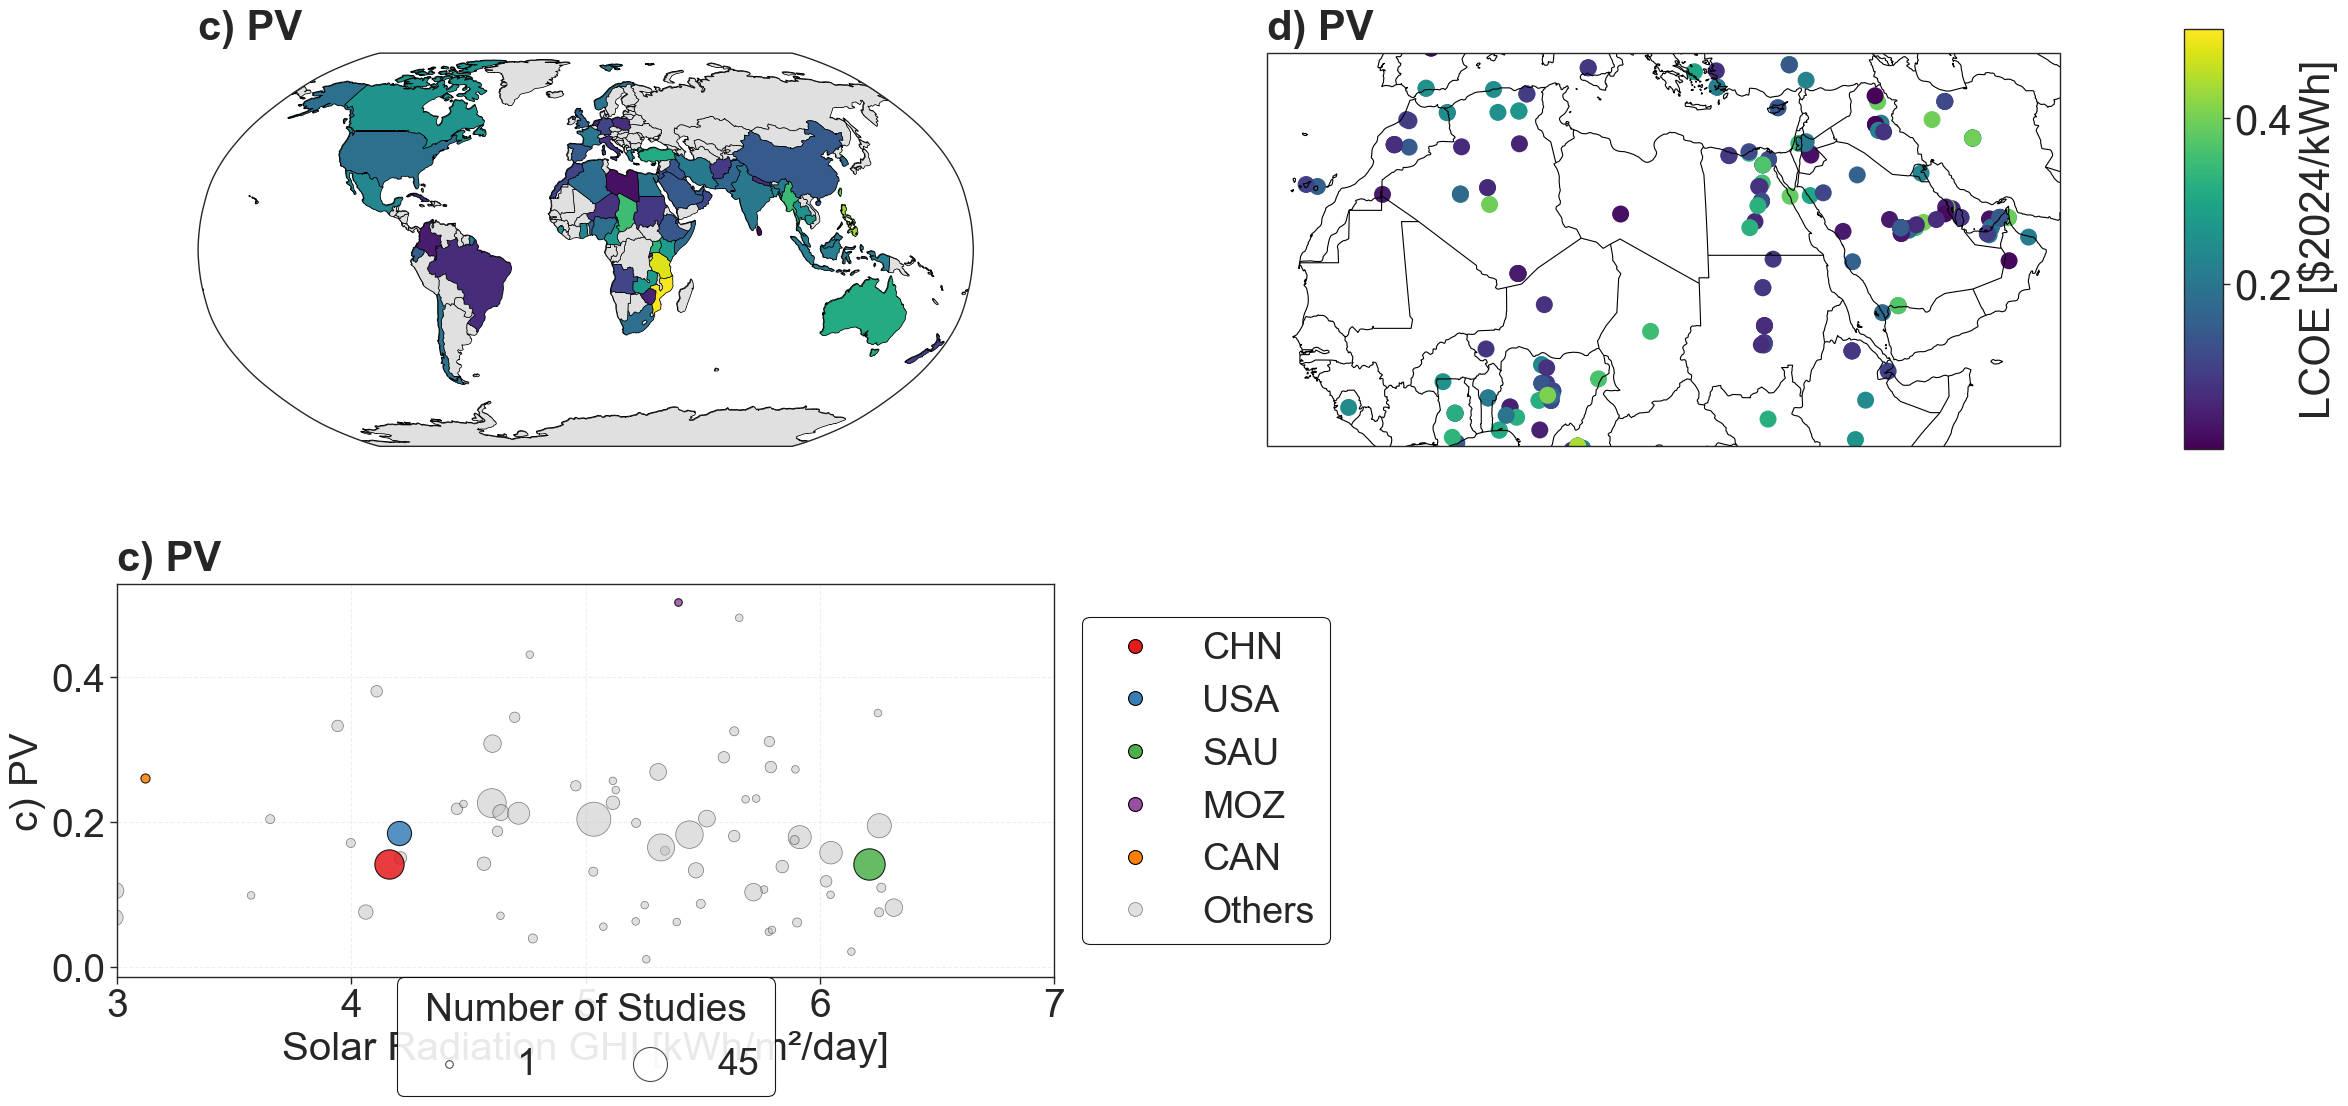

In [8]:
datasets = [
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'choropleth',
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'd) PV',
    'plot_mode': 'points',
    'spatial_extent': [-20, 60, 5, 40]
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'size',
    'ghi_data_path': "../data/visualisation_files/country_GHI_mean.xlsx",
    'highlight_countries': ['CHN', 'USA', 'SAU', 'MOZ', 'CAN'],
    'x_range': [3,7]
    },
]

fig, data_tables = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="LCOE [$2024/kWh]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=30,
)

#fig.savefig("../data/figures/results/spatial/lcoe_pv_new.pdf", bbox_inches='tight')

In [9]:
# Display scatter data (avg_value, n_datapoints, ghi per country)
for title, df_table in data_tables.items():
    print(f"\n--- {title} ---")
    display(df_table.sort_values("n_datapoints", ascending=False).head(20))


--- c) PV ---


,country,avg_value,n_datapoints,ghi,bubble_size
28,IND,0.204120,45,5.034712,600.000000
59,SAU,0.142630,38,6.207105,509.318182
9,CHN,0.141814,33,4.159152,444.545455
5,BGD,0.226365,32,4.599339,431.590909
47,NGA,0.182874,29,5.442919,392.727273
53,PAK,0.165206,28,5.321666,379.772727
18,EGY,0.195143,22,6.253116,302.045455
70,USA,0.185530,22,4.202620,302.045455
17,DZA,0.179380,20,5.913517,276.136364
2,ARE,0.157959,19,6.047002,263.181818


### **Investigate Results**